In [18]:
import numpy as np                        # arrays and linear algebra (eigenvalues)
from scipy.integrate import solve_ivp     # solves differential equations numerically
import matplotlib.pyplot as plt           # plotting

# Index 0 = Wood, 1 = Fire, 2 = Earth, 3 = Metal, 4 = Water.
NAMES  = ["Wood", "Fire", "Earth", "Metal", "Water"]
COLORS = ["green", "red", "magenta", "black", "blue"]

# Baseline parameter values
P_LIN = (1, 1, 1, 1, 1, 1)          # Lin's "Case 1": a=b=c=d=g=h=1
P_SAT = (2, 0.5, 1, 0.5, 0.3)       # ours: a=2, k=0.5, c=1, g=0.5, h=0.3


In [19]:
def mother_of(i):
    # The organ that NOURISHES organ i (one step back around the Sheng cycle).
    return (i - 1) % 5

def child_of(i):
    # The organ that organ i nourishes (one step forward around the Sheng cycle).
    return (i + 1) % 5

def controller_of(i):
    # The organ that RESTRAINS organ i (two steps back: the Ke pentagram).
    return (i - 2) % 5

def target_of(i):
    # The organ that organ i restrains (two steps forward).
    return (i + 2) % 5

# Print the whole table so the wiring is visible rather than implied.
print(f"{'organ':>7s} {'mother':>8s} {'child':>8s} {'controller':>11s} {'target':>8s}")
for i in range(5):
    print(f"{NAMES[i]:>7s} {NAMES[mother_of(i)]:>8s} {NAMES[child_of(i)]:>8s}"
          f" {NAMES[controller_of(i)]:>11s} {NAMES[target_of(i)]:>8s}")


  organ   mother    child  controller   target
   Wood    Water     Fire       Metal    Earth
   Fire     Wood    Earth       Water    Metal
  Earth     Fire    Metal        Wood    Water
  Metal    Earth    Water        Fire     Wood
  Water    Metal     Wood       Earth     Fire


In [20]:
# ---------------------------------------------------------------------------
# Lin's bilinear model
# Six coefficients: a=gain, b=saturation, c=nourishment received,
#                   d=restraint received, g=cost of feeding child,
#                   h=cost of restraining target
# ---------------------------------------------------------------------------

def rhs_lin(t, x, a, b, c, d, g, h):
    # `t` (time) is unused, but solve_ivp needs it as the first parameter
    rates = np.zeros(5)

    for i in range(5):                        # handle one organ at a time
        me         = x[i]                     # this organ's current level
        mother     = x[mother_of(i)]          # look up its four neighbours
        child      = x[child_of(i)]
        controller = x[controller_of(i)]
        target     = x[target_of(i)]

        growth      =  a * me                 # self-production, proportional to size
        crowding    = -b * me * me            # self-limiting: grows as the square
        nourishment =  c * me * mother        # fed by mother -- note: a PRODUCT
        suppressed  = -d * me * controller    # held down by its controller
        feeding     = -g * me * child         # pays a cost to feed its child
        restraining = -h * me * target        # pays a cost to restrain its target

        rates[i] = growth + crowding + nourishment + suppressed + feeding + restraining

    return rates


# ---------------------------------------------------------------------------
# Our saturating model
# Five coefficients: a=self-production, k=self-limitation, c=nourishment,
#                    g=over-acting cost, h=restraint received
# ---------------------------------------------------------------------------

def rhs_sat(t, x, a, k, c, g, h):
    rates = np.zeros(5)

    for i in range(5):
        me         = x[i]
        mother     = x[mother_of(i)]
        controller = x[controller_of(i)]
        target     = x[target_of(i)]

        growth   =  a * me                    # same self-production as before
        crowding = -k * me * me               # same self-limitation

        nourishment = c * mother / (1 + me)

        # Over-acting: the cost of controlling a WEAK target is high, because
        # dividing by a small number gives a large result.
        over_acting = -g * me / (1 + target)

        # Ordinary restraint
        suppressed = -h * me * controller

        rates[i] = growth + crowding + nourishment + over_acting + suppressed

    return rates

# Quick check that both functions run and return five numbers.
test_state = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
print("Lin  rates:", np.round(rhs_lin(0, test_state, *P_LIN), 3))
print("Ours rates:", np.round(rhs_sat(0, test_state, *P_SAT), 3))


Lin  rates: [ -4. -24. -30. -32. -30.]
Ours rates: [ 2.675 -0.867  0.85  -2.8   -7.167]


# The balanced state

- **Lin:** the algebra gives $x^{*} = a/(b+d+g+h-c)$. If the bottom is zero or
  negative there is no sensible answer, so we return "not a number".
- **Ours:** the algebra gives a quadratic, and we take its positive root.


In [21]:
def balanced_state_lin(a, b, c, d, g, h):
    # Setting every organ equal reduces Lin's system to  0 = a*x - M*x^2,
    # where M is the total of all the losses minus the gain from the mother.
    M = b + d + g + h - c

    if M <= 0:
        # A non-positive M means no positive balanced state exists (and in fact the
        # solution runs away to infinity). np.nan = "not a number" flags this.
        return np.nan

    return a / M                              # the balanced level


def balanced_state_sat(a, k, c, g, h):
    # For our model the same substitution gives a quadratic  A*x^2 + B*x + C = 0.
    A = k + h
    B = (k + h) - a
    C = -(a + c - g)

    discriminant = B * B - 4 * A * C          # the bit under the square root
    if discriminant < 0:
        return np.nan                         # no real solution at all

    root = (-B + np.sqrt(discriminant)) / (2 * A)   # the "+" root is the larger one
    return root if root > 0 else np.nan       # only a positive level is meaningful


# Compute both and compare to the closed form we derived by hand.
x_lin = balanced_state_lin(*P_LIN)
x_sat = balanced_state_sat(*P_SAT)
print(f"Lin  balanced state: {x_lin:.6f}")
print(f"Ours balanced state: {x_sat:.6f}")
print(f"   With our coefficients our formula is 3/4 + sqrt(59)/4 = {0.75 + np.sqrt(59)/4:.6f}")


Lin  balanced state: 0.333333
Ours balanced state: 2.670286
   With our coefficients our formula is 3/4 + sqrt(59)/4 = 2.670286


In [22]:
def jacobian_lin(level, a, b, c, d, g, h):
    # `level` is the balanced value; at the balanced state every organ equals it.
    x = np.full(5, level)                     # an array of five copies
    J = np.zeros((5, 5))                      # empty 5x5 table to fill in

    for i in range(5):
        # --- diagonal entry: how organ i responds to a nudge in ITSELF ---
        # Differentiate each of its own terms with respect to x[i].
        J[i, i] = (a                          # from  a*x
                   - 2 * b * x[i]             # from -b*x^2
                   + c * x[mother_of(i)]      # from  c*x*mother
                   - d * x[controller_of(i)]  # from -d*x*controller
                   - g * x[child_of(i)]       # from -g*x*child
                   - h * x[target_of(i)])     # from -h*x*target

        # --- off-diagonal entries: response to a nudge in each NEIGHBOUR ---
        J[i, mother_of(i)]     +=  c * x[i]   # differentiate c*x*mother wrt mother
        J[i, controller_of(i)] += -d * x[i]
        J[i, child_of(i)]      += -g * x[i]
        J[i, target_of(i)]     += -h * x[i]

    return J


def jacobian_sat(level, a, k, c, g, h):
    x = np.full(5, level)
    J = np.zeros((5, 5))

    for i in range(5):
        me         = x[i]
        mother     = x[mother_of(i)]
        target     = x[target_of(i)]
        controller = x[controller_of(i)]

        # Diagonal. The two fraction terms need the quotient rule:
        #   d/dx [ c*mother/(1+x) ]  = -c*mother/(1+x)^2
        #   d/dx [ -g*x/(1+target) ] = -g/(1+target)
        J[i, i] = (a
                   - 2 * k * me
                   - c * mother / (1 + me)**2
                   - g / (1 + target)
                   - h * controller)

        # Off-diagonals, one per neighbour that appears in organ i's equation.
        J[i, mother_of(i)]     +=  c / (1 + me)                 # wrt the mother
        J[i, target_of(i)]     +=  g * me / (1 + target)**2     # wrt the target
        J[i, controller_of(i)] += -h * me                       # wrt the controller

    return J


def max_growth_rate(model, params):
    """The single number that decides stability: the largest real part of any
    eigenvalue. Negative means stable. Returns nan if no balanced state exists."""
    if model == "lin":
        level = balanced_state_lin(*params)
        if np.isnan(level): return np.nan
        J = jacobian_lin(level, *params)
    else:
        level = balanced_state_sat(*params)
        if np.isnan(level): return np.nan
        J = jacobian_sat(level, *params)

    eigenvalues = np.linalg.eigvals(J)         # NumPy does the hard part
    return max(eigenvalues.real)               # ".real" drops the imaginary part


Checking


In [23]:
def finite_difference_jacobian(rhs, x, params, eps=1e-7):
    """Estimate the Jacobian numerically, using only the model function."""
    n = len(x)
    J = np.zeros((n, n))
    baseline = rhs(0, x, *params)              # rates before any nudge

    for j in range(n):                         # nudge each input in turn
        nudged = np.array(x, dtype=float)
        nudged[j] += eps                       # tiny push to organ j
        J[:, j] = (rhs(0, nudged, *params) - baseline) / eps   # rise over run

    return J

# Compare hand-derived against numerical at 100 random states, FOR BOTH MODELS.
rng = np.random.default_rng(0)
worst = {"Lin": 0.0, "Ours": 0.0}

for _ in range(100):
    # A random state that is NOT the balanced one, so the test is not accidentally
    # passing because every organ happens to be equal.
    state = rng.uniform(0.2, 3.0, 5)

    # --- Lin: 6 random coefficients ---
    p_lin = tuple(rng.uniform(0.1, 2.0, 6))
    hand_lin = jacobian_lin(state, *p_lin)
    num_lin  = finite_difference_jacobian(rhs_lin, state, p_lin)
    worst["Lin"] = max(worst["Lin"], np.max(np.abs(hand_lin - num_lin)))

    # --- Ours: 5 random coefficients ---
    p_sat = tuple(rng.uniform(0.1, 2.0, 5))
    hand_sat = jacobian_sat(state, *p_sat)
    num_sat  = finite_difference_jacobian(rhs_sat, state, p_sat)
    worst["Ours"] = max(worst["Ours"], np.max(np.abs(hand_sat - num_sat)))

for name, err in worst.items():
    verdict = "OK" if err < 1e-4 else "PROBLEM -- check the algebra"
    print(f"Largest disagreement, {name:5s} Jacobian: {err:.2e}   {verdict}")


Largest disagreement, Lin   Jacobian: 2.42e-07   OK
Largest disagreement, Ours  Jacobian: 3.42e-07   OK


## Stability


In [24]:
# Eigenvalues for each model at its own baseline.
eig_lin = np.linalg.eigvals(jacobian_lin(x_lin, *P_LIN))
eig_sat = np.linalg.eigvals(jacobian_sat(x_sat, *P_SAT))

# Print them sorted from most dangerous (largest real part) downwards.
print("Lin eigenvalues:")
for e in sorted(eig_lin, key=lambda z: -z.real):
    print(f"   {e.real:+.4f} {e.imag:+.4f}i")
print(f"   -> largest real part {max(eig_lin.real):+.4f}"
      f"  =>  {'UNSTABLE' if max(eig_lin.real) > 0 else 'stable'}")

print("\nOur eigenvalues:")
for e in sorted(eig_sat, key=lambda z: -z.real):
    print(f"   {e.real:+.4f} {e.imag:+.4f}i")
print(f"   -> largest real part {max(eig_sat.real):+.4f}"
      f"  =>  {'unstable' if max(eig_sat.real) > 0 else 'STABLE'}")


Lin eigenvalues:
   +0.2060 +0.6340i
   +0.2060 -0.6340i
   -0.5393 +0.3919i
   -0.5393 -0.3919i
   -1.0000 +0.0000i
   -> largest real part +0.2060  =>  UNSTABLE

Our eigenvalues:
   -1.1537 +0.2700i
   -1.1537 -0.2700i
   -2.2353 +0.0000i
   -2.2432 +1.0163i
   -2.2432 -1.0163i
   -> largest real part -1.1537  =>  STABLE


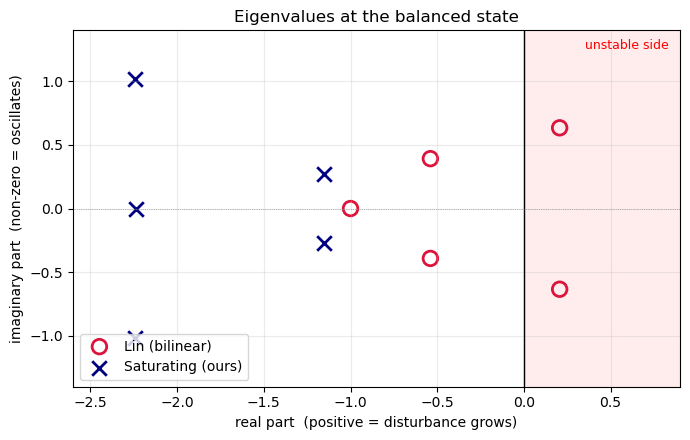

In [25]:
# ---------------------------------------------------------------------------
# PLOT: the eigenvalues on the complex plane.
# Horizontal axis = real part (growth/decay), vertical = imaginary (oscillation).
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.axvline(0, color='black', lw=1)                      # the stability dividing line
ax.axhline(0, color='gray', lw=0.5, ls=':')             # cosmetic horizontal axis
ax.fill_betweenx([-1.5, 1.5], 0, 3, color='red', alpha=0.07)   # shade unstable side
ax.text(0.35, 1.25, 'unstable side', color='red', fontsize=9)

# Lin's five eigenvalues as hollow circles.
ax.scatter(eig_lin.real, eig_lin.imag, s=110, facecolor='none',
           edgecolor='crimson', lw=2, label='Lin (bilinear)')
# Ours as crosses.
ax.scatter(eig_sat.real, eig_sat.imag, s=110, marker='x',
           color='navy', lw=2, label='Saturating (ours)')

ax.set_xlabel("real part  (positive = disturbance grows)")
ax.set_ylabel("imaginary part  (non-zero = oscillates)")
ax.set_title("Eigenvalues at the balanced state")
ax.set_xlim(-2.6, 0.9); ax.set_ylim(-1.4, 1.4)
ax.legend(loc='lower left'); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()


# Pertubation


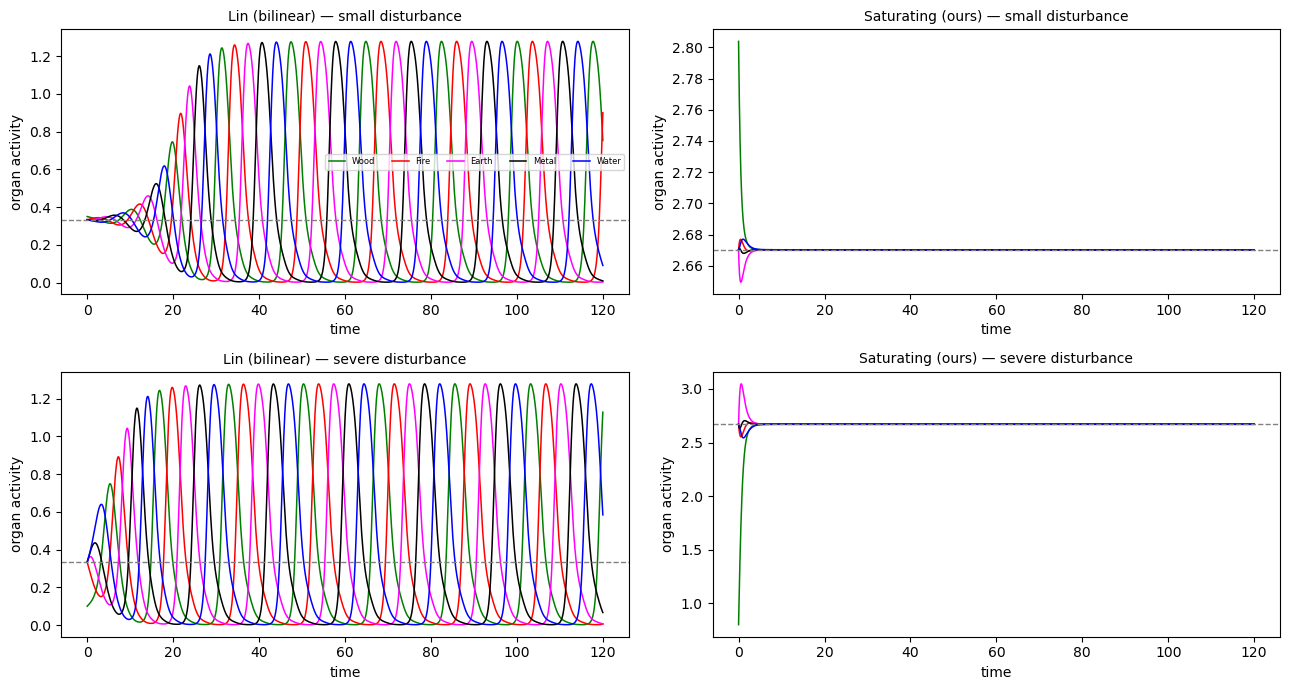

                              start       end   outcome
Lin, small                   0.0167    0.8776   does NOT return
Lin, severe                  0.2333    0.9899   does NOT return
Ours, small                  0.1335    0.0000   returns to balance
Ours, severe                 1.8692    0.0000   returns to balance


In [26]:
def poke_and_watch(rhs, params, balanced_level, organ=0, size="small", duration=120):
    """Start at balance, disturb one organ, and record how far from balance we stay."""

    start = np.full(5, float(balanced_level))     # begin exactly at balance

    if size == "small":
        start[organ] += 0.05 * balanced_level     # raise that organ by 5%
    else:
        start[organ] *= 0.30                      # or cut it to 30% (a deficiency)

    # Solve the differential equation forward in time.
    solution = solve_ivp(rhs,                     # the model
                         (0, duration),           # from time 0 to `duration`
                         start,                   # starting state
                         args=params,             # the model's coefficients
                         t_eval=np.linspace(0, duration, 2000),   # when to record
                         rtol=1e-9, atol=1e-11)   # accuracy settings

    # Distance from balance at each recorded time.
    deviation = np.linalg.norm(solution.y - balanced_level, axis=0)
    return solution, deviation


# Run all four combinations and plot them.
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

for col, (label, rhs, params, level) in enumerate([
        ("Lin (bilinear)",     rhs_lin, P_LIN, x_lin),
        ("Saturating (ours)",  rhs_sat, P_SAT, x_sat)]):

    for row, size in enumerate(["small", "severe"]):
        solution, deviation = poke_and_watch(rhs, params, level, size=size)
        ax = axes[row, col]

        for i in range(5):                        # one line per organ
            ax.plot(solution.t, solution.y[i], color=COLORS[i], label=NAMES[i], lw=1.1)

        ax.axhline(level, color='gray', ls='--', lw=1)    # the balanced level
        ax.set_title(f"{label} — {size} disturbance", fontsize=10)
        ax.set_xlabel("time"); ax.set_ylabel("organ activity")
        if row == 0 and col == 0:
            ax.legend(ncol=5, fontsize=6)

plt.tight_layout(); plt.show()

# Numerical summary of the same runs.
print(f"{'':26s}{'start':>9s}{'end':>10s}   outcome")
for label, rhs, params, level, size in [
        ("Lin, small",     rhs_lin, P_LIN, x_lin, "small"),
        ("Lin, severe",    rhs_lin, P_LIN, x_lin, "severe"),
        ("Ours, small",    rhs_sat, P_SAT, x_sat, "small"),
        ("Ours, severe",   rhs_sat, P_SAT, x_sat, "severe")]:
    _, deviation = poke_and_watch(rhs, params, level, size=size)
    verdict = "returns to balance" if deviation[-1] < 1e-3 else "does NOT return"
    print(f"{label:26s}{deviation[0]:9.4f}{deviation[-1]:10.4f}   {verdict}")


### Other organs


In [27]:
print("Final deviation after poking each organ in turn:\n")
print(f"{'organ':>8s}{'Lin small':>12s}{'Lin severe':>12s}{'Ours small':>12s}{'Ours severe':>13s}")

results = {}
for i in range(5):                                  # poke each organ in turn
    row = [NAMES[i]]
    for rhs, params, level in [(rhs_lin, P_LIN, x_lin), (rhs_sat, P_SAT, x_sat)]:
        for size in ["small", "severe"]:
            _, deviation = poke_and_watch(rhs, params, level, organ=i, size=size)
            row.append(deviation[-1])
            results.setdefault((str(params), size), []).append(deviation[-1])
    print(f"{row[0]:>8s}{row[1]:12.4f}{row[2]:12.4f}{row[3]:12.4f}{row[4]:13.4f}")

print("\nSpread across the five organs (should be ~0 if the wiring is symmetric):")
for key, finals in results.items():
    spread = max(finals) - min(finals)
    print(f"   spread = {spread:.2e}  -> {'symmetric, as expected' if spread < 1e-6 else 'PROBLEM'}")


Final deviation after poking each organ in turn:

   organ   Lin small  Lin severe  Ours small  Ours severe
    Wood      0.8776      0.9899      0.0000       0.0000
    Fire      0.8776      0.9899      0.0000       0.0000
   Earth      0.8776      0.9899      0.0000       0.0000
   Metal      0.8776      0.9899      0.0000       0.0000
   Water      0.8776      0.9899      0.0000       0.0000

Spread across the five organs (should be ~0 if the wiring is symmetric):
   spread = 0.00e+00  -> symmetric, as expected
   spread = 1.11e-16  -> symmetric, as expected
   spread = 0.00e+00  -> symmetric, as expected
   spread = 0.00e+00  -> symmetric, as expected


## Checking other coefficients


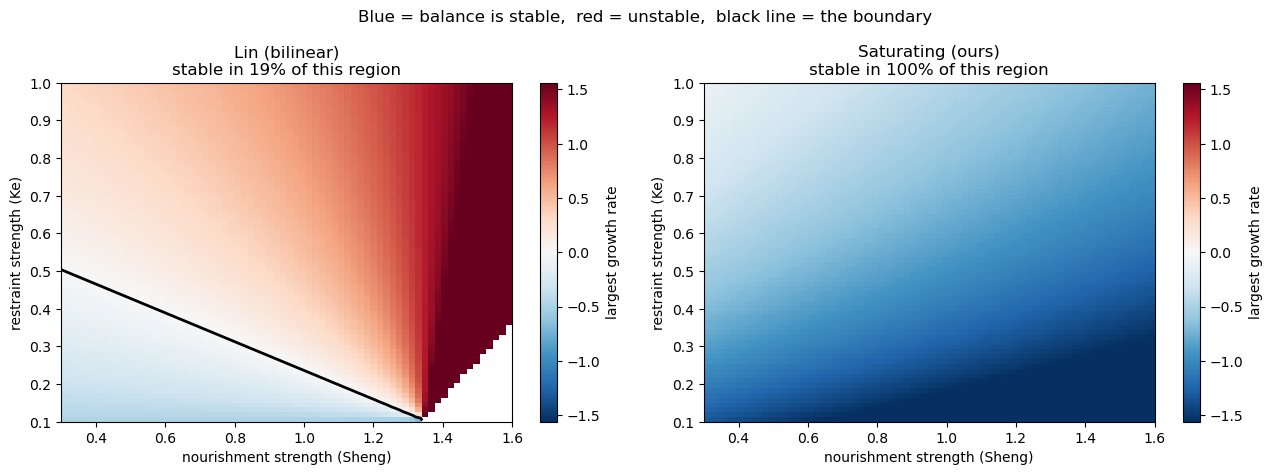

In [28]:
GRID = 70                                   # 70 x 70 points; raise for a finer picture

sheng_values   = np.linspace(0.3, 1.6, GRID)   # nourishment strength, left to right
restraint_values = np.linspace(0.1, 1.0, GRID) # restraint strength, bottom to top

# Two empty grids to fill with the "largest growth rate" at each point.
map_lin = np.full((GRID, GRID), np.nan)
map_sat = np.full((GRID, GRID), np.nan)

for row, restraint in enumerate(restraint_values):
    for col, sheng in enumerate(sheng_values):
        # Lin: parameters are (a, b, c, d, g, h); we vary c and d.
        map_lin[row, col] = max_growth_rate("lin", (1.5, 0.65, sheng, restraint, 0.3, 0.3))
        # Ours: parameters are (a, k, c, g, h); we vary c and h.
        map_sat[row, col] = max_growth_rate("sat", (1.5, 0.65, sheng, 0.3, restraint))

# Lin's values explode near the point where his balanced state stops existing,
# which would wash out all the colour. Clip the scale to a sensible range.
scale = np.nanpercentile(np.abs(np.concatenate([map_lin.ravel(), map_sat.ravel()])), 90)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, grid_values, title in [(axes[0], map_lin, "Lin (bilinear)"),
                               (axes[1], map_sat, "Saturating (ours)")]:

    picture = ax.imshow(np.clip(grid_values, -scale, scale),
                        origin="lower", aspect="auto", cmap="RdBu_r",
                        vmin=-scale, vmax=scale,
                        extent=[sheng_values[0], sheng_values[-1],
                                restraint_values[0], restraint_values[-1]])

    # Draw the dividing line where the growth rate is exactly zero.
    ax.contour(sheng_values, restraint_values, grid_values,
               levels=[0], colors='black', linewidths=2)

    percent_stable = 100 * np.nanmean(grid_values < 0)
    ax.set_xlabel("nourishment strength (Sheng)")
    ax.set_ylabel("restraint strength (Ke)")
    ax.set_title(f"{title}\nstable in {percent_stable:.0f}% of this region")
    fig.colorbar(picture, ax=ax, label="largest growth rate")

plt.suptitle("Blue = balance is stable,  red = unstable,  black line = the boundary")
plt.tight_layout(); plt.show()


## Parameter sets


In [29]:
def random_parameters(rng, scheme):
    """Draw one set of six physiological quantities, shared by both models."""

    if scheme == "tiered":
        # Each quantity gets its own range, reflecting how large it should be.
        return {"SELF":  rng.uniform(1.0, 2.0),   # self-production: the biggest
                "SHENG": rng.uniform(0.5, 1.5),   # nourishment: next
                "SAT":   rng.uniform(0.3, 1.0),   # self-limitation
                "RESTR": rng.uniform(0.2, 0.8),   # normal restraint
                "TGT":   rng.uniform(0.1, 0.5),   # over-acting: smallest
                "CHILD": rng.uniform(0.1, 0.5)}

    # Otherwise draw everything from one common range and, for "ordered",
    # simply throw the draw away unless it happens to obey the ordering.
    while True:
        values = rng.uniform(0.1, 2.0, 6)
        SELF, SAT, SHENG, RESTR, TGT, CHILD = values

        if scheme == "uniform":
            pass                                  # accept anything
        elif scheme == "ordered":
            if not (SELF > SHENG > RESTR > TGT):
                continue                          # reject and draw again

        return {"SELF": SELF, "SAT": SAT, "SHENG": SHENG,
                "RESTR": RESTR, "TGT": TGT, "CHILD": CHILD}


def to_model_parameters(model, q):
    """Translate the shared quantities into each model's own coefficient order."""
    if model == "lin":
        # Lin's order is (a, b, c, d, g, h).
        return (q["SELF"], q["SAT"], q["SHENG"], q["RESTR"], q["CHILD"], q["TGT"])
    # Ours is (a, k, c, g, h) -- no CHILD term.
    return (q["SELF"], q["SAT"], q["SHENG"], q["TGT"], q["RESTR"])


def run_random_test(scheme, n_draws=1500, seed=3):
    """Count how often each model has a stable balanced state."""
    rng = np.random.default_rng(seed)             # seeded, so results repeat exactly
    tally = {"lin": {"stable": 0, "valid": 0},
             "sat": {"stable": 0, "valid": 0}}

    for _ in range(n_draws):
        q = random_parameters(rng, scheme)        # one shared physiological draw

        for model in ("lin", "sat"):
            growth = max_growth_rate(model, to_model_parameters(model, q))
            if np.isnan(growth):
                continue                          # no balanced state: skip this draw
            tally[model]["valid"] += 1
            if growth < 0:
                tally[model]["stable"] += 1

    return tally


results = {}
print(f"{'sampling scheme':>18s}{'Lin':>10s}{'Ours':>10s}")
for scheme in ["uniform", "ordered", "tiered"]:
    tally = run_random_test(scheme)
    results[scheme] = tally
    pct_lin  = 100 * tally["lin"]["stable"]  / max(tally["lin"]["valid"], 1)
    pct_sat  = 100 * tally["sat"]["stable"]  / max(tally["sat"]["valid"], 1)
    print(f"{scheme:>18s}{pct_lin:>9.1f}%{pct_sat:>9.1f}%")

print("\nNotice that the ORDERED scheme RAISES Lin's score. The physiological")
print("ordering favours his model, which makes this the conservative comparison.")


   sampling scheme       Lin      Ours
           uniform     22.8%     94.3%
           ordered     46.8%     91.7%
            tiered     23.6%     99.0%

Notice that the ORDERED scheme RAISES Lin's score. The physiological
ordering favours his model, which makes this the conservative comparison.


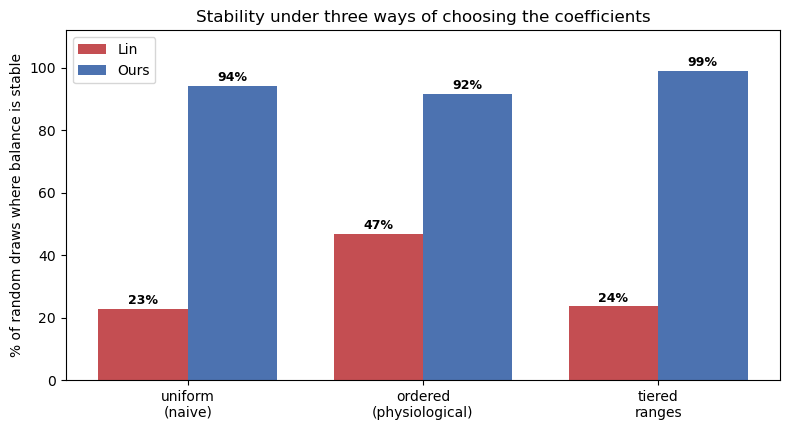

In [17]:
# ---------------------------------------------------------------------------
# PLOT: the headline bar chart.
# ---------------------------------------------------------------------------
schemes = ["uniform", "ordered", "tiered"]
lin_pcts = [100 * results[s]["lin"]["stable"] / max(results[s]["lin"]["valid"], 1)
            for s in schemes]
sat_pcts = [100 * results[s]["sat"]["stable"] / max(results[s]["sat"]["valid"], 1)
            for s in schemes]

positions = np.arange(len(schemes))       # x positions: 0, 1, 2
width = 0.38                              # how wide each bar is

fig, ax = plt.subplots(figsize=(8, 4.4))
bars_lin = ax.bar(positions - width/2, lin_pcts, width, label="Lin", color="#c44e52")
bars_sat = ax.bar(positions + width/2, sat_pcts, width, label="Ours", color="#4c72b0")

for bar in list(bars_lin) + list(bars_sat):        # write the number on each bar
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f"{bar.get_height():.0f}%", ha="center", fontweight="bold", fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels(["uniform\n(naive)", "ordered\n(physiological)", "tiered\nranges"])
ax.set_ylabel("% of random draws where balance is stable")
ax.set_ylim(0, 112)
ax.set_title("Stability under three ways of choosing the coefficients")
ax.legend()
plt.tight_layout(); plt.show()
